In [1]:
#from bai_utils import *
from tbp_utils import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

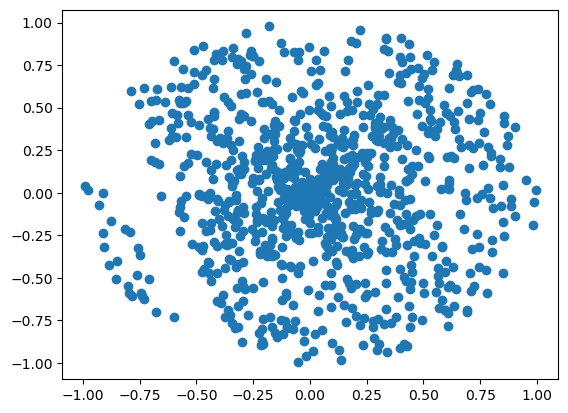

In [3]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .95)
#np.sort(np.abs(x @ theta - rho))[:5]# < 0.01
plt.scatter(x[np.abs(x @ theta - rho) > 2, 0], x[np.abs(x @ theta - rho) > 2, 1])

In [14]:
mean_list = defaultdict(list)
mean_hat_list1 = defaultdict(list)
mean_hat_list2 = defaultdict(list)
gap_list = defaultdict(list)
tau_list1 = defaultdict(list)
succ_list1 = defaultdict(list)
g_arms_list1 = defaultdict(list)
perf_list1 = defaultdict(list)

tau_list2 = defaultdict(list)
succ_list2 = defaultdict(list)
rho_list = defaultdict(list)
epsilon_list = defaultdict(list)

for eta in (1 / np.linspace(.1,10,10)):
    for i in trange(10):
        x, y, theta = gen_data(100, p=2, scale=20)

        rho = np.quantile(x @ theta, .95)
        rho_list[eta].append(rho)

        x = x[np.abs(x @ theta - rho) > eta, :]

        epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
        epsilon_list[eta].append(epsilon)
        gap_list[eta].append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
        mean_list[eta].append(x @ theta)
        m, d = x.shape
        prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }

        prob = linear_discover(**prob_dict)
        t_prob = deepcopy(prob)
        solver = G_allocation(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, 0.05, sampling_rule=1)
        tau_list1[eta].append(tau)
        g_arms_list1[eta].append(g_arms)
        perf_list1[eta].append(perf)
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list1[eta].append(x @ solver.theta_hat)

        #t_prob = deepcopy(prob)
        #solver = lazy_TS(t_prob)
        #reg, rwd, best, tau = solver.run(100, 0.05, 2)
        #tau_list2.append(tau)
        #succ_list2.append(best == prob.best_arm)
        #mean_hat_list2.append(x @ solver.theta_hat)

100%|███████████████████████████████████████████| 10/10 [00:01<00:00,  7.29it/s]


In [24]:
perf_list1

defaultdict(list,
            {10.0: [(0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0)],
             0.8333333333333333: [(0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0)],
             0.4347826086956521: [(0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0)],
             0.2941176470588235: [(0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0),
              (0, 0)],
             0.2222222222222222:

In [16]:
np.nanmean(pd.DataFrame(tau_list1),0)

array([ 3.1, 22.4, 43. , 34.2, 63.5, 62.2, 67. , 71.2, 61.8, 84. ])

In [17]:
[min([np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]) for eta in (1 / np.linspace(.1,10,10))]

[10.06312377765861,
 0.8437105596662544,
 0.47453581364561437,
 0.36972528138753447,
 0.2911734652714699,
 0.19692025603000296,
 0.22923943055840645,
 0.13337578194264132,
 0.135961333578976,
 0.12781599362436857]

In [18]:
taus_ = np.array([[1/np.mean([np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]), np.mean(tau_list1[eta])]  for eta in (1 / np.linspace(.1,10,10))])
taus_+1


array([[ 1.09699669,  4.1       ],
       [ 1.93743448, 23.4       ],
       [ 2.30456872, 44.        ],
       [ 2.48941041, 35.2       ],
       [ 3.09409877, 64.5       ],
       [ 2.47596673, 63.2       ],
       [ 3.12331673, 68.        ],
       [ 2.68413221, 72.2       ],
       [ 2.67463624, 62.8       ],
       [ 3.39930344, 85.        ]])

In [19]:
[np.mean([1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)])  for eta in (1 / np.linspace(.1,10,10))]


[0.09705745860880448,
 0.9643710555530799,
 1.490887797957904,
 1.5989856176783253,
 2.4271230808533097,
 2.5377828643865694,
 2.750095683391639,
 3.3781872069407752,
 2.483291631274666,
 3.7872925904933794]

In [20]:
[np.nanmean(np.array([1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))]


[0.09705745860880448,
 0.9643710555530799,
 1.490887797957904,
 1.5989856176783253,
 2.4271230808533097,
 2.5377828643865694,
 2.750095683391639,
 3.3781872069407752,
 2.483291631274666,
 3.7872925904933794]

In [33]:
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus = np.array([np.nanmean(np.array([(np.sum(1/np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
np.round(1 + taus, 2)

array([[ 1.27,  4.1 ],
       [ 4.16, 23.4 ],
       [ 6.21, 44.  ],
       [ 7.98, 35.2 ],
       [12.4 , 64.5 ],
       [16.93, 63.2 ],
       [16.16, 68.  ],
       [34.29, 72.2 ],
       [18.52, 62.8 ],
       [32.98, 85.  ]])

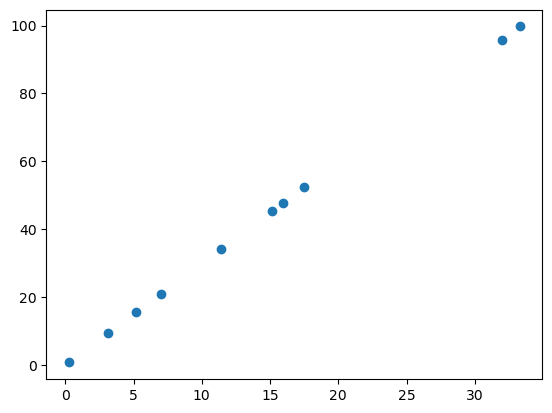

In [22]:
(taus_[8,1] - taus_[0,1]) / (taus_[8,0] - taus_[0,0])

37.20748519405883

In [30]:
np.log(1/0.05)

2.995732273553991

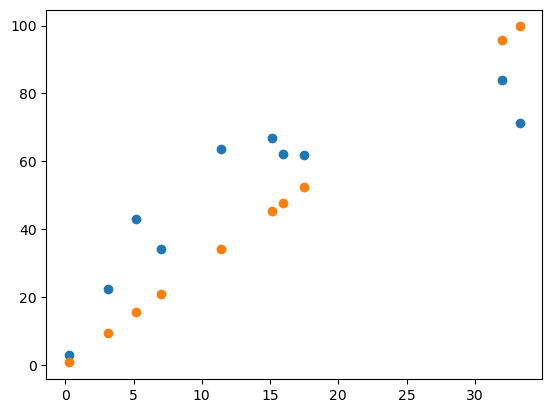

In [40]:
plt.scatter(taus[:,0], taus[:,1])
plt.scatter(taus[:,0], taus[:,0] * np.log(1/0.05))
#plt.scatter(taus_[:,0], taus_[:,1])
#plt.plot(np.linspace(0,5), 30*np.linspace(0,5))

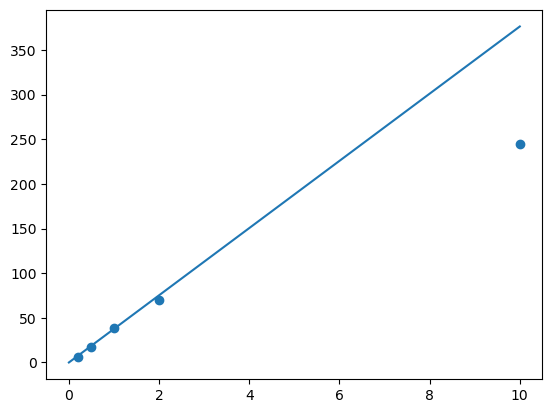

In [129]:
plt.scatter([.2,.5,1,2,10],[6.6,17.7,38.9,70.5,245.3])
plt.plot(np.linspace(0,10), 37.64*np.linspace(0,10))

In [24]:
(17.7 - 6.6) / (.5 - .2)

37.0

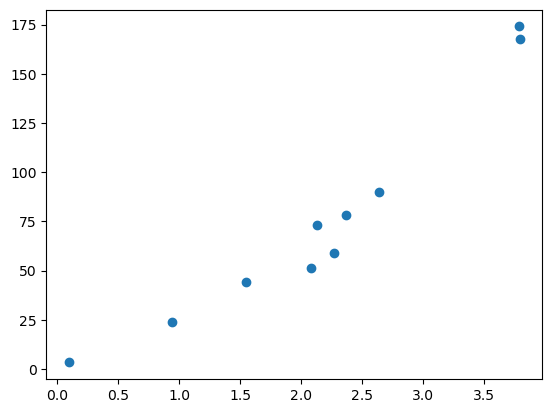

In [128]:
plt.scatter(taus[:,0], taus[:,1])

In [114]:
set(np.arange(8))> set(np.where(np.arange(10) > 5)[0])

False

In [107]:
np.setdiff1d(np.where(np.arange(10) > 5)[0], np.arange(10))

array([], dtype=int64)

In [43]:
mean_list[0][~good_arms].shape

(948,)

In [44]:
mean_list[0][good_arms].shape

(52,)

In [127]:
for eta in (1 / np.linspace(.1,10,10)):
    for i in range(10):
        good_arms = mean_hat_list1[eta][i] > rho_list[eta][i]
        #print((mean_list[10.0][i][good_arms] + epsilon_list[10.0][i] <= rho_list[10.0][i]).sum(), (mean_list[10.0][i][~good_arms] - epsilon_list[10.0][i] > rho_list[10.0][i]).sum())
        print((mean_list[eta][i][good_arms] + 0 <= rho_list[eta][i]).sum(), (mean_list[eta][i][~good_arms] - 0 > rho_list[eta][i]).sum())


0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0


In [78]:
epsilon = 0
rest_list1 = []
rest_list2 = []
for j in range(10):
    list_1 = []
    list_2 = []
    #j = 4
    mean_norm = (mean_list[j] - min(mean_list[j])) / (max(mean_list[j]) - min(mean_list[j]))
    mean_hat_norm = (mean_hat_list1[j] - min(mean_hat_list1[j])) / (max(mean_hat_list1[j]) - min(mean_hat_list1[j]))

    for rho in np.linspace(0, 1, 100):
        good_arms = mean_hat_norm > rho
        list_1.append((mean_norm[good_arms] + epsilon <= rho).sum())
        list_2.append((mean_norm[~good_arms] - epsilon > rho).sum())
    
    rest_list1.append(list_1)
    rest_list2.append(list_2)
    #plt.scatter(np.linspace(0,1, 100), list_1)    
    
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list1) > 1).mean(0), label='false good')
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list2) > 1).mean(0), label='false bad')
plt.legend()

ValueError: min() arg is an empty sequence

In [4]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .5)
x = x[np.abs(x @ theta - rho) > 5, :]  
epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
m, d = x.shape
prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
          }

prob = linear_discover(**prob_dict)
t_prob = deepcopy(prob)
solver = G_allocation(t_prob, rho)
reg, rwd, best, tau = solver.run(1000, 0.05, epsilon=epsilon, sampling_rule=1)   

In [13]:
epsilon

0.11207914691634865

In [6]:
tau

nan

In [7]:
len(solver.prob.actions)

1000

In [22]:
delta = 0.05
t = 1000
x = solver.prob.x
A_inv = solver.sigma_hat
C = np.log(solver.prob.m ** 2 / delta) / np.log(t)
theta_hat = solver.theta_hat
m = solver.prob.m
        
        #gaps = ((x - x[:,None]).reshape(-1, 2) @ theta_hat).reshape(m,m)
gap = np.abs(x @ theta_hat - solver.rho).min()
        
norms = (np.sqrt(x[:,None] @ A_inv @ x[:,:,None]).flatten())
        
(norms * C < np.abs(x @ theta_hat - solver.rho) + epsilon).sum()# == m - 1

527

In [21]:
m

527

In [11]:
C

2.2482170753630246

In [12]:
rho

0.0411185039419723

In [14]:
np.abs(x @ theta_hat - solver.rho)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]] + 0.05

array([], dtype=float64)

In [15]:
(np.round(np.sort(x @ theta), 1)).std()

11.207914691634866

In [16]:
(norms * C)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]]

array([], dtype=float64)

In [17]:
np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]

array([], dtype=int64)